In [1]:
from langgraph.graph import StateGraph,START,END
from pydantic import BaseModel,Field
from typing import TypedDict,Literal,Annotated
from langchain_cohere import ChatCohere
import operator

In [14]:
model_name_generator="command-a-03-2025"
model_name_evaulator="command-a-reasoning-08-2025"
model_name_optimizer="command-a-plus-05-2026"

In [12]:
class evalOutputSchema(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final evaluation result.")
    feedback: str = Field(..., description="feedback for the tweet.")


In [15]:
generatorModel=ChatCohere(model=model_name_generator,temperature=0.9)
evaluationModel=ChatCohere(model=model_name_evaulator,temperature=0)
optimizerModel=ChatCohere(model=model_name_optimizer,temperature=0.6)

In [2]:
class state(TypedDict):
    generatedTweet:str
    eval:Literal["positive","negative"]
    optimizedTweet:str
    interation:int
    maxIteration:int
    tweetHistory:Annotated[list[str],operator.add]
    feedBackHistory:Annotated[list[str],operator.add]

In [8]:
def generateTweet(state:TypedDict)->dict:
    return ""

In [9]:
def evaluateTweet(state:TypedDict)->dict:
    return ""

In [10]:
def optimizeTweet(state:TypedDict)->dict:
    return ""

In [11]:
def checkTweet(state:TypedDict)->dict:
    return ""

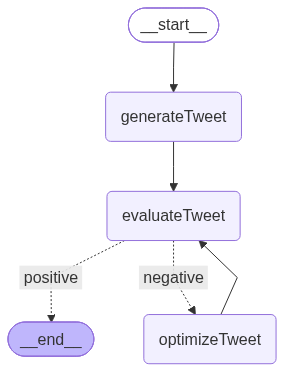

In [7]:
graph=StateGraph(state)
graph.add_node("generateTweet",generateTweet)
graph.add_node("evaluateTweet",evaluateTweet)
graph.add_node("optimizeTweet",optimizeTweet)
graph.add_edge(START,"generateTweet")
graph.add_edge("generateTweet","evaluateTweet")
graph.add_conditional_edges("evaluateTweet",checkTweet,{
   "positive":END,
   "negative":"optimizeTweet"
})
graph.add_edge("optimizeTweet","evaluateTweet")
workflow=graph.compile()
workflow